Universidade Federal do ABC (UFABC)  
Curso: Bacharelado em Ciências Econômicas  
Disciplina: Macroeconomia I 
Período: 3º Quadrimestre de 2026  
Turmas: NA1ESHC022-17SB 
Aulas 03: Contabilidade Social e Ciclos de Negócios 
  
Prof. Dr. Elson Rodrigo de Souza Santos  
WhatsApp: (41) 9 8454 0549 | E-mail: elson129@gmail.com ou elson.rodrigo@ufabc.edu.br | Repositório: github.com/elsonr29  
setembro de 2026  

#### **Aula 03 - Ciclos de negócios e o hiato do produto**

**Resumo**
    
O script apresentado é referente à aula 03 sobre ciclo de negócios e hiato do produto. Para isso, apresentamos brevemente os dados sobre produto, mensurações e preços para economia brasileira. Por fim, identificamos os ciclos econômicos a partir do hiato do produto, separando as flutuações de curto prazo e a tendência de longo prazo.

**Referência:**

Paulani, L. M., & Braga, M. B. (2013). A nova contabilidade social: Uma introdução à macroeconomia (3ª ed.). Saraiva. **Cap. 1 - contabilidade social; cap. 2 - Contas nacionais: estrutura básica; Cap. 3 - Contas nacionais: problemas de mensuração**.
	
Bernanke, B. S., Abel, A. B., \& Croushore, D. (2020). Macroeconomics. (10th ed.). Pearson. **Cap. 8 - Business Cycles**

**Dados:**

Instituto Brasileiro de Geografia e Estatística. (2026). Sistema de Contas Nacionais (SCN) [Base de dados]. https://www.ibge.gov.br/estatisticas/economicas/contas-nacionais.html

Instituto de Pesquisa Econômica Aplicada. (2026). Ipeadata [Base de dados]. http://www.ipeadata.gov.br/

Banco Central do Brasil. (2026). Sistema Gerenciador de Séries Temporais (SGS) [Base de dados]. https://www3.bcb.gov.br/sgspub/



**Sumário**

1. Pacotes e dados
2. Produto real, nominal e deflator
3. Hiato do produto


#### **1. Pacotes e dados**

Partimos dos seguintes pacotes

- **Numpy:** suporte para arrays multidimensionais e matrizes, com funções matemáticas de alto desempenho para cálculos avançados e operações de álgebra linear;
- **Pandas:** ferramenta estrutural para manipulação e análise de dados;
- **Matplotlib:** visualização de dados;
- **statsmodels:** pacote com modelos e filtros estatśiticos.

In [20]:
# Pacotes

!pip install numpy pandas matplotlib statsmodels

Defaulting to user installation because normal site-packages is not writeable


Os dados estão organizados em três blocos:

* **data_hist**: dados históricos de 1900-2025, compreendendo o PIB real e nominal, variação real, PIB per capita e deflator do PIB;
* **data_comp**: dados entre 1947-2025, compreendendo os principais componentes do PIB;
* **data_out**: outros dados relevantes,tal como divida pública, taxa de desemprego e setor externo.


**Observação:** para o objetivo do trabalho, utilizamos uma base compilada em formato Excel (aula03_data.xlsx), também disponibilizada em anexo. No entanto, é possível extrair os dados diretamente das fontes a partir da API. Para cada ponto, utilizamos um bloco diferente de dados.

#### **2. Produto real, nominal e deflator**

Apresentamos uma série de gráficos com dados históricos sobre produto, renda per capita e delfator do pib entre 1900-2024

* Produto preços nominal ou preços correntes;
* Produto real ou preços constantes;
* Taxa de variação real do produto;
* Produto per capita em US$ vs R$ preços correntes;
* Deflator do pib

**Importante:** usamos a planilha data_hist



In [2]:
# carregar dados

import pandas as pd

# carregar planilha 'aula03_data'

df = '/home/elson29r/Área de trabalho/Academico/6 docencia e aulas/ufabc_2026_disciplinas/ufabc_2026.3_macro_I/model_data/aula03_data.xlsx'

# Especificar o dataframe
df_hist = pd.read_excel(df, sheet_name= 'data_hist' )

# Exibir as cinco primeiras linhas para conferência
print(df_hist.head())

    ano  pib_txreal   pib_per_nom  pib_per_uss  preco_deflator   pib_nominal  \
0  1901   14.364641  7.381005e-17     0.039034      -17.761557  1.323363e-12   
1  1902   -0.483092  6.584817e-17     0.042112       -7.692308  1.215665e-12   
2  1903    1.941748  6.636918e-17     0.043456        1.923077  1.263102e-12   
3  1904    1.428571  6.914718e-17     0.046379        5.974843  1.357693e-12   
4  1905    3.286385  6.199792e-17     0.042624      -10.385757  1.256671e-12   

   pib_real_2010  
0   24820.992393  
1   24701.084217  
2   25180.716921  
3   25540.441448  
4   26379.798679  


### **Distorções do Produto Nominal**

O produto nominal ou a preços correntes sofre duas grandes distorções:

1. Sofre influência da variação de preços, fator que dificulta visualizar as mudanças na economia real;
2. Quanto maior a inflação ou aumento de preços, maior o produto nominal independente da economia real;
3. Quando ampliamos o período, fica cada vez mais difícil identificar as mudanças. Tal efeito é agravado no caso do Brasil devido aos episódios de alta inflação ou hiperinflação. Por isso, a análise no gráfico passa a fazer algum sentido após o Plano Real em 1994.

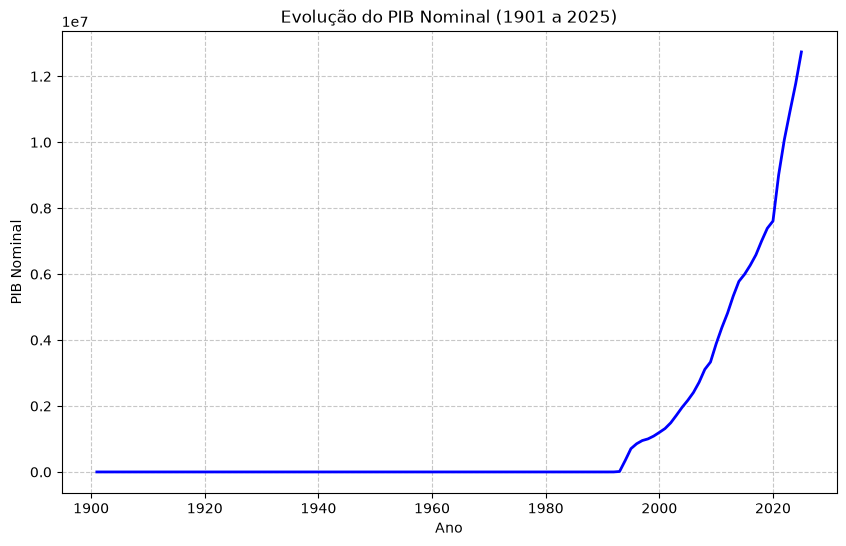

In [3]:
# Produto aos preços correntes 'pib_nominal'

import matplotlib.pyplot as plt

anos = range(1901, 2026)

plt.figure(figsize=(10, 6))

plt.plot(anos, df_hist['pib_nominal'], color='blue', linewidth=2)

plt.title('Evolução do PIB Nominal (1901 a 2025)')
plt.xlabel('Ano')
plt.ylabel('PIB Nominal')

plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

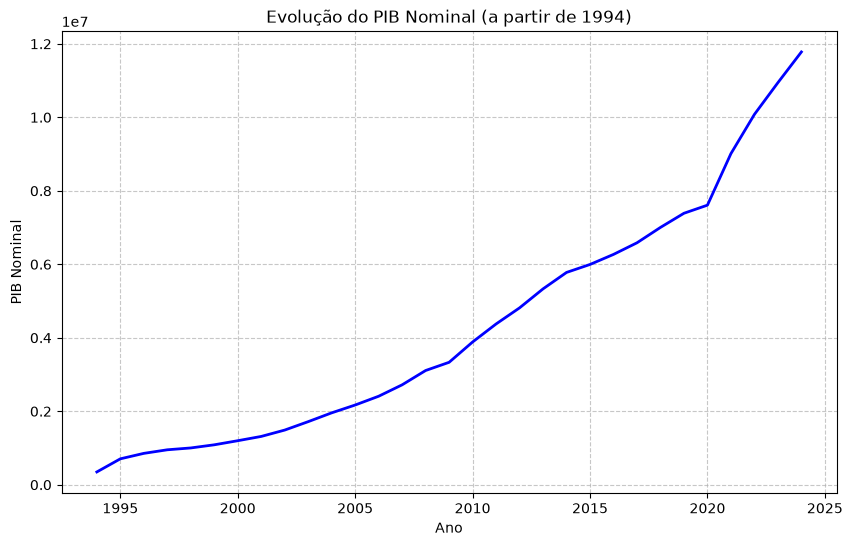

In [4]:
# Produto aos preços correntes 'pib_nominal' após 1994

import matplotlib.pyplot as plt

pib_recente = df_hist['pib_nominal'].iloc[93:124] 

anos = range(1994, 1994 + len(pib_recente))

plt.figure(figsize=(10, 6))

plt.plot(anos, pib_recente, color='blue', linewidth=2)

plt.title('Evolução do PIB Nominal (a partir de 1994)')
plt.xlabel('Ano')
plt.ylabel('PIB Nominal')

plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

### **Produto Real ou a Preços Constantes**

O produto real indica preços constantes com base em um ano específico. Assim, permite realizar a comparação real entre os anos. No entanto, existem distorções:

1. A metodologia de cálculo do produto muda ao longo do tempo devido a avanços da tecnologia, a novos produtos e a novos hábitos de consumo;
2. A métrica permite calcular a taxa de crescimento real do produto ao longo do tempo, mas a análise pode ser enganosa dada a mudança de metodologia e da estrutura da economia;
3. A busca por padronizar a metodologia exige extrapolações que podem acentuar as distorções. Por exemplo, o aparelho celular não existia na década de 1940, e dispositivos similares não tinham a importância de hoje;
4. A escolha do deflator para padronizar os preços também pode afetar o produto real e a taxa de crescimento.

**Obs.:** As distorções podem ser ainda maiores durante a comparação entre diferentes países com moedas distintas.





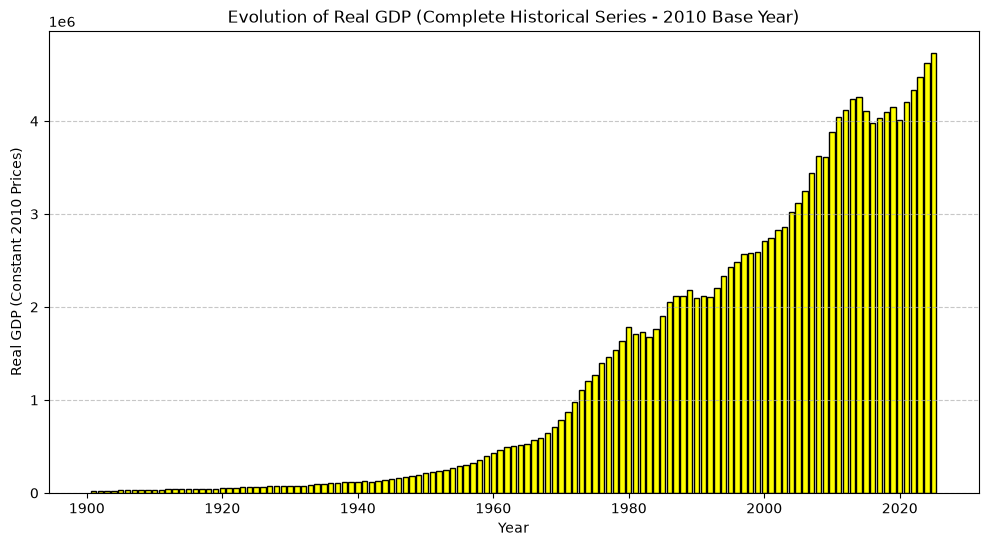

In [5]:
# Produto real (preços 2010) 

import matplotlib.pyplot as plt

total_real_gdp = df_hist['pib_real_2010']

years = range(1901, 1901 + len(total_real_gdp))

plt.figure(figsize=(12, 6))

plt.bar(years, total_real_gdp, color='yellow', edgecolor='black')

plt.title('Evolution of Real GDP (Complete Historical Series - 2010 Base Year)')
plt.xlabel('Year')
plt.ylabel('Real GDP (Constant 2010 Prices)')

plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

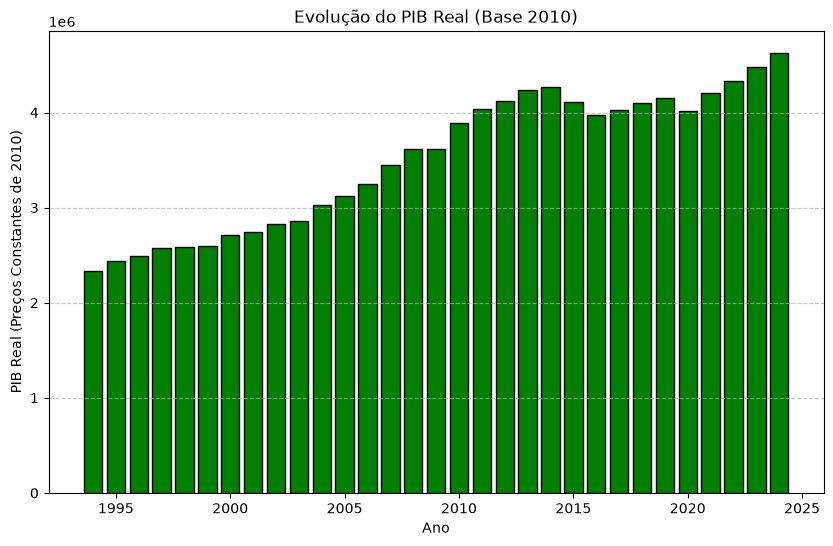

In [6]:
# Produto real (preços 2010) - após 1994

import matplotlib.pyplot as plt

pib_real = df_hist['pib_real_2010'].iloc[93:124] 

anos = range(1994, 1994 + len(pib_real))

plt.figure(figsize=(10, 6))

plt.bar(anos, pib_real, color='green', edgecolor='black')

plt.title('Evolução do PIB Real (Base 2010)')
plt.xlabel('Ano')
plt.ylabel('PIB Real (Preços Constantes de 2010)')

plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()


#### **Taxa de crescimento real**

Observem nos gráficos anteriores que o produto real tende a crescer ao longo do tempo. Tal comportamento constitui algo esperado à medida que o país acumula as condições de crescimento de longo prazo, oriundas do capital físico, do capital humano, de avanços tecnológicos e de outros fatores. Isto é, a sociedade tende a alcançar uma maior renda agregada, elemento que resulta em um maior produto.

Dessa forma, os macroeconomistas utilizam a taxa de crescimento como método para separar o curto e o longo prazo. Portanto, existe uma taxa de crescimento de longo prazo determinada pelos fatores reais e pelas variações que incorporam as flutuações de curto prazo. Por isso, a taxa de crescimento recebe tanta ênfase como parâmetro de comparação entre os períodos.


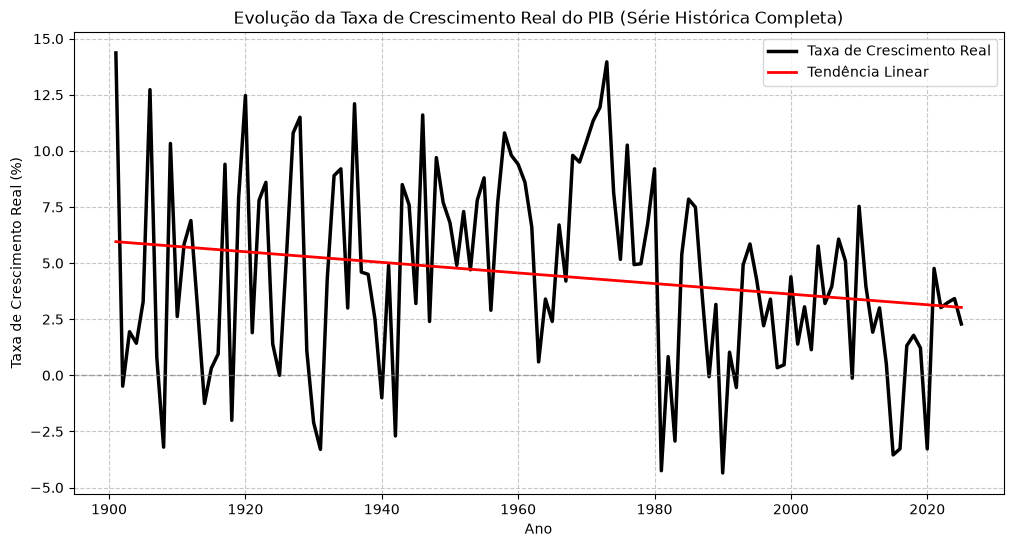

In [7]:
# Taxa de crescimento do produto

import matplotlib.pyplot as plt
import numpy as np

pib_txreal = df_hist['pib_txreal']

anos = range(1901, 1901 + len(pib_txreal))

coeficientes = np.polyfit(anos, pib_txreal, 1)
funcao_tendencia = np.poly1d(coeficientes)
linha_tendencia = funcao_tendencia(anos)

plt.figure(figsize=(12, 6))

plt.plot(anos, pib_txreal, color='black', linewidth=2.5, label='Taxa de Crescimento Real')

plt.plot(anos, linha_tendencia, color='red', linewidth=2, label='Tendência Linear')

plt.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)

plt.title('Evolução da Taxa de Crescimento Real do PIB (Série Histórica Completa)')
plt.xlabel('Ano')
plt.ylabel('Taxa de Crescimento Real (%)')
plt.legend()

plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

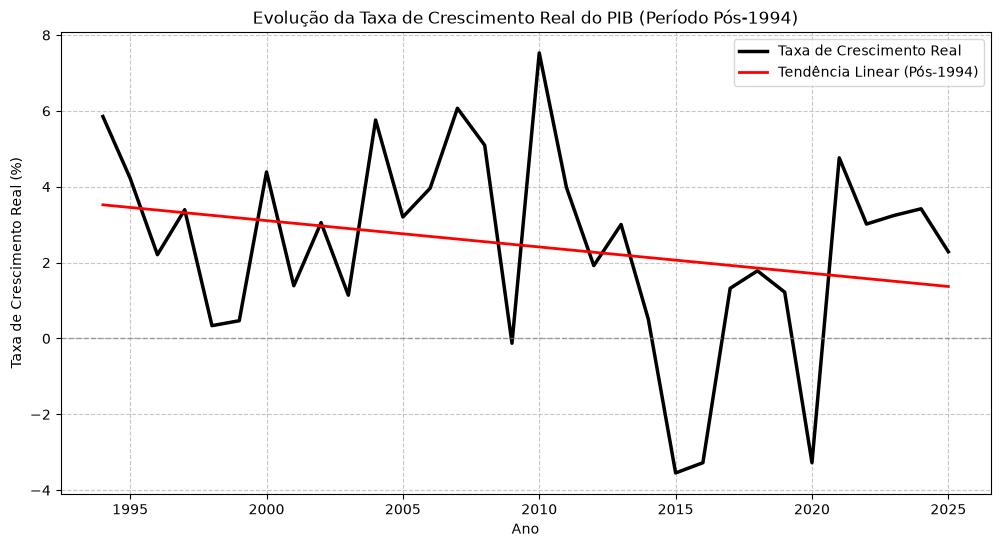

In [8]:
# Taxa de crescimento do produto - pós-1994

import matplotlib.pyplot as plt
import numpy as np

pib_txreal_recente = df_hist['pib_txreal'].iloc[93:]

anos = range(1994, 1994 + len(pib_txreal_recente))

coeficientes = np.polyfit(anos, pib_txreal_recente, 1)
funcao_tendencia = np.poly1d(coeficientes)
linha_tendencia = funcao_tendencia(anos)

plt.figure(figsize=(12, 6))

plt.plot(anos, pib_txreal_recente, color='black', linewidth=2.5, label='Taxa de Crescimento Real')

plt.plot(anos, linha_tendencia, color='red', linewidth=2, label='Tendência Linear (Pós-1994)')

plt.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)

plt.title('Evolução da Taxa de Crescimento Real do PIB (Período Pós-1994)')
plt.xlabel('Ano')
plt.ylabel('Taxa de Crescimento Real (%)')
plt.legend()

plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

#### **Produto per capita**

O produto per capita constitui uma forma de minimizar as distorções ao ponderar a produção pela população. Tal indicador serve como instrumento para o longo prazo e para a análise do bem-estar social, mas não se mostra recomendável para captar choques de curto prazo.

In [9]:
# obter o produto per capita real

pop = df_hist['pib_nominal'] / df_hist['pib_per_nom']

df_hist['pib_per_real'] = df_hist['pib_real_2010'] / pop

print(df_hist[['pib_per_nom', 'pib_nominal', 'pib_real_2010', 'pib_per_real']].head())


    pib_per_nom   pib_nominal  pib_real_2010  pib_per_real
0  7.381005e-17  1.323363e-12   24820.992393      1.384381
1  6.584817e-17  1.215665e-12   24701.084217      1.337969
2  6.636918e-17  1.263102e-12   25180.716921      1.323111
3  6.914718e-17  1.357693e-12   25540.441448      1.300773
4  6.199792e-17  1.256671e-12   26379.798679      1.301449


In [10]:
df_hist

,ano,pib_txreal,pib_per_nom,pib_per_uss,preco_deflator,pib_nominal,pib_real_2010,pib_per_real
0,1901,14.364641,7.381005e-17,0.039034,-17.761557,1.323363e-12,2.482099e+04,1.384381
1,1902,-0.483092,6.584817e-17,0.042112,-7.692308,1.215665e-12,2.470108e+04,1.337969
2,1903,1.941748,6.636918e-17,0.043456,1.923077,1.263102e-12,2.518072e+04,1.323111
3,1904,1.428571,6.914718e-17,0.046379,5.974843,1.357693e-12,2.554044e+04,1.300773
4,1905,3.286385,6.199792e-17,0.042624,-10.385757,1.256671e-12,2.637980e+04,1.301449
...,...,...,...,...,...,...,...,...
120,2021,4.762604,4.422367e+01,8.197118,13.047271,9.012142e+06,4.206934e+06,20.643934
121,2022,3.016694,4.963383e+01,9.611199,8.570279,1.007968e+07,4.333844e+06,21.340493
122,2023,3.241655,5.364454e+01,10.741010,5.159501,1.094334e+07,4.474332e+06,21.933284
123,2024,3.419315,5.732999e+01,10.638467,4.079674,1.177925e+07,4.626275e+06,22.516226


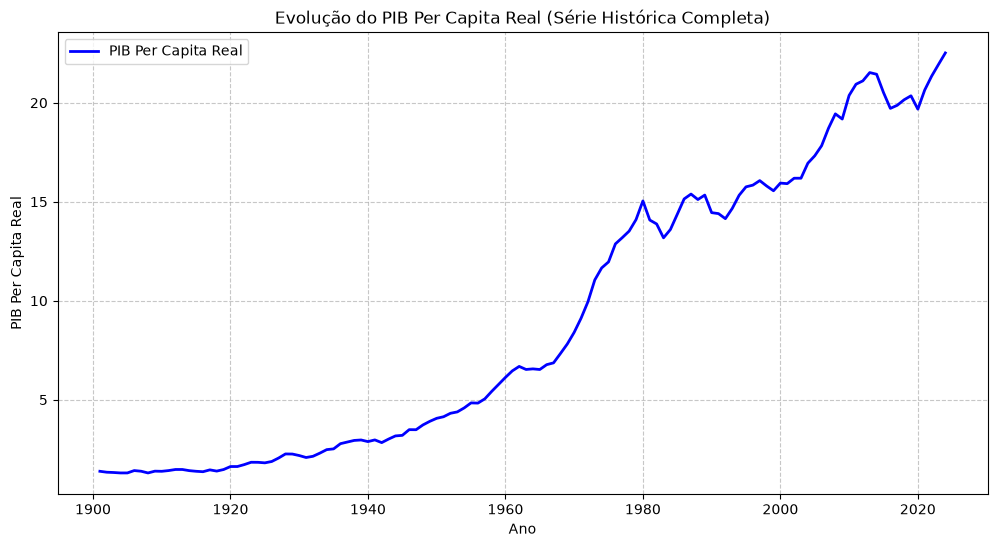

In [11]:
# Evolução do pib per capita real

import matplotlib.pyplot as plt

# Extrair a série completa de dados para a variável pib_per_real
pib_per_real_total = df_hist['pib_per_real']

# Criar a sequência temporal exata atrelada ao tamanho total da série (a partir de 1901)
anos = range(1901, 1901 + len(pib_per_real_total))

# Definir o tamanho da figura com largura expandida
plt.figure(figsize=(12, 6))

# Criar o gráfico de linha relacionando os anos à variável pib_per_real
plt.plot(anos, pib_per_real_total, color='blue', linewidth=2, label='PIB Per Capita Real')

# Adicionar título, rótulos e legenda aos eixos
plt.title('Evolução do PIB Per Capita Real (Série Histórica Completa)')
plt.xlabel('Ano')
plt.ylabel('PIB Per Capita Real')
plt.legend()

# Inserir grade de fundo para facilitar a leitura dos valores
plt.grid(True, linestyle='--', alpha=0.7)

# Exibir o gráfico final
plt.show()


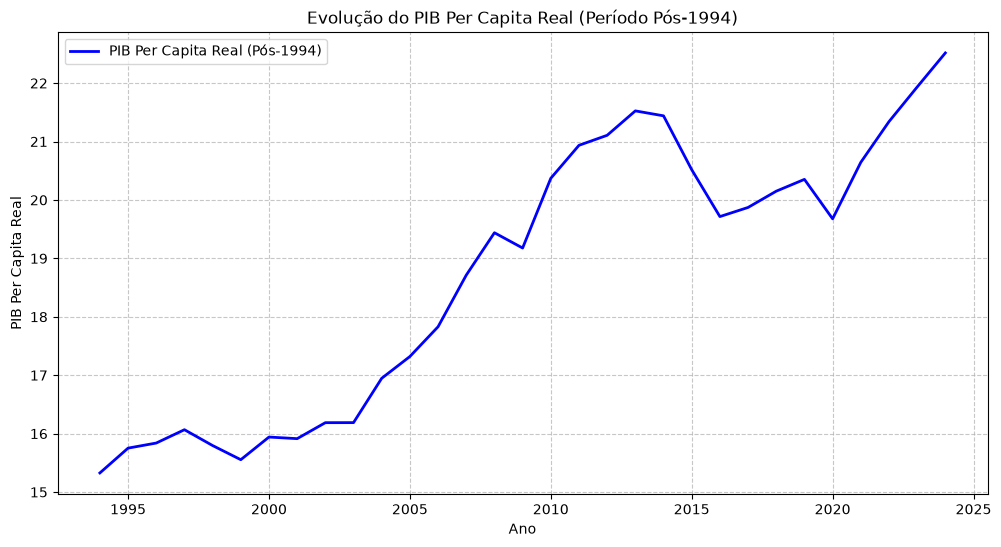

In [12]:
import matplotlib.pyplot as plt

# Extrair a série de dados para a variável pib_per_real a partir de 1994
# O índice 93 equivale ao ano de 1994 em uma série iniciada em 1901
pib_per_real_recente = df_hist['pib_per_real'].iloc[93:]

# Criar a sequência temporal exata a partir de 1994 atrelada ao tamanho da série filtrada
anos = range(1994, 1994 + len(pib_per_real_recente))

# Definir o tamanho da figura com largura expandida
plt.figure(figsize=(12, 6))

# Criar o gráfico de linha relacionando os anos à variável pib_per_real no período recente
plt.plot(anos, pib_per_real_recente, color='blue', linewidth=2, label='PIB Per Capita Real (Pós-1994)')

# Adicionar título, rótulos e legenda aos eixos
plt.title('Evolução do PIB Per Capita Real (Período Pós-1994)')
plt.xlabel('Ano')
plt.ylabel('PIB Per Capita Real')
plt.legend()

# Inserir grade de fundo para facilitar a leitura dos valores
plt.grid(True, linestyle='--', alpha=0.7)

# Exibir o gráfico final
plt.show()

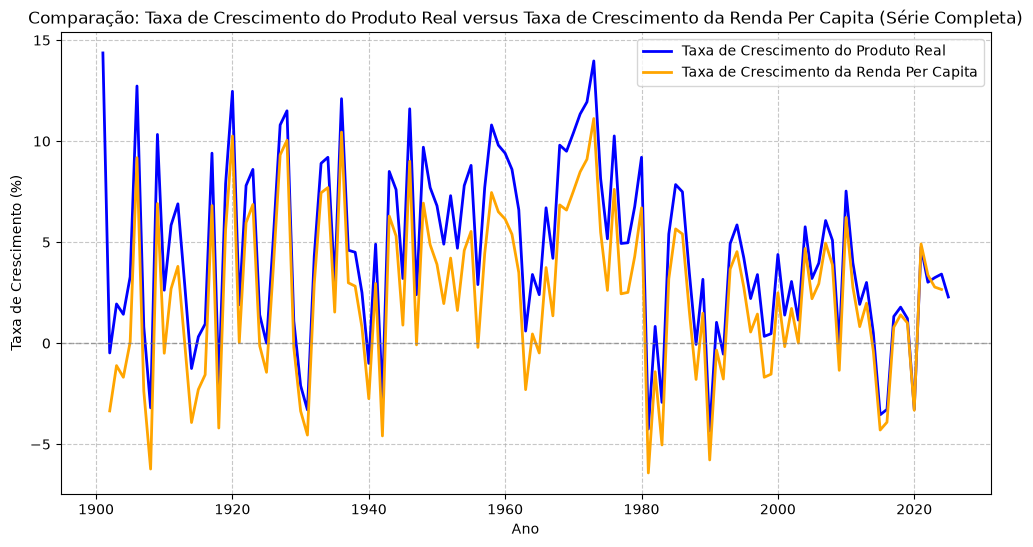

In [13]:
# Taxa de crescimento do PIB e renda per capita - Série Histórica Completa

import matplotlib.pyplot as plt

pib_per_real_total = df_hist['pib_per_real']

taxa_crescimento_per_capita = pib_per_real_total.pct_change() * 100

pib_txreal_total = df_hist['pib_txreal']

anos = range(1901, 1901 + len(pib_per_real_total))

plt.figure(figsize=(12, 6))

plt.plot(anos, pib_txreal_total, color='blue', linewidth=2, label='Taxa de Crescimento do Produto Real')

plt.plot(anos, taxa_crescimento_per_capita, color='orange', linewidth=2, label='Taxa de Crescimento da Renda Per Capita')

plt.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)

plt.title('Comparação: Taxa de Crescimento do Produto Real versus Taxa de Crescimento da Renda Per Capita (Série Completa)')
plt.xlabel('Ano')
plt.ylabel('Taxa de Crescimento (%)')
plt.legend()

plt.grid(True, linestyle='--', alpha=0.7)

# Exibir o gráfico final
plt.show()

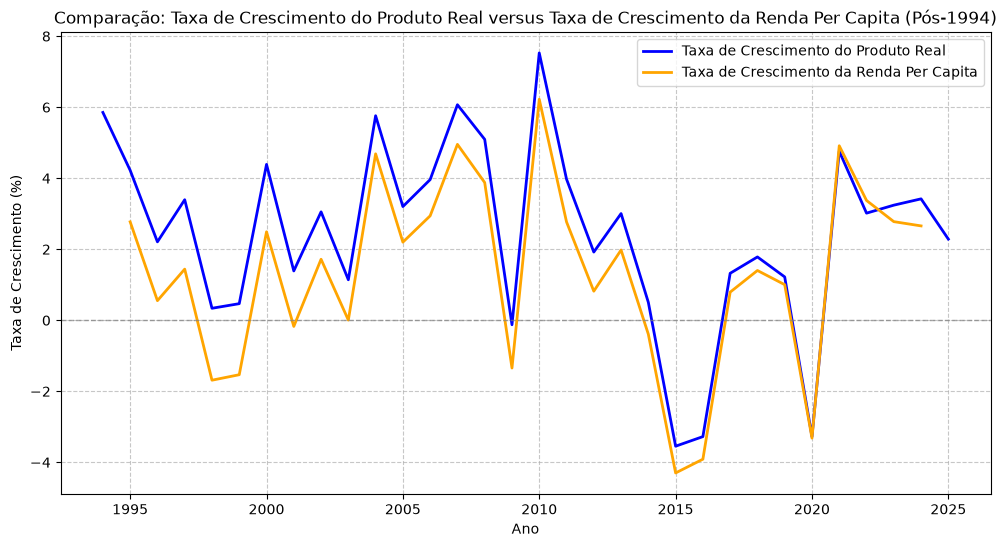

In [14]:
# Taxa de crescimento do pib e renda per capita - pós=1994

import matplotlib.pyplot as plt

pib_per_real_recente = df_hist['pib_per_real'].iloc[93:]

taxa_crescimento_per_capita = pib_per_real_recente.pct_change() * 100

pib_txreal_recente = df_hist['pib_txreal'].iloc[93:]

anos = range(1994, 1994 + len(pib_per_real_recente))

plt.figure(figsize=(12, 6))

plt.plot(anos, pib_txreal_recente, color='blue', linewidth=2, label='Taxa de Crescimento do Produto Real')

plt.plot(anos, taxa_crescimento_per_capita, color='orange', linewidth=2, label='Taxa de Crescimento da Renda Per Capita')

plt.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.7)

plt.title('Comparação: Taxa de Crescimento do Produto Real versus Taxa de Crescimento da Renda Per Capita (Pós-1994)')
plt.xlabel('Ano')
plt.ylabel('Taxa de Crescimento (%)')
plt.legend()

plt.grid(True, linestyle='--', alpha=0.7)

# Exibir o gráfico final
plt.show()

#### **Deflator e preços**

O deflator do PIB constitui o índice padrão para captar as variações de preços e construir o produto real. No entanto, dependendo da aplicação, o índice pode ser alterado. Por exemplo, em questões fiscais, mostra-se comum o uso do IPCA.

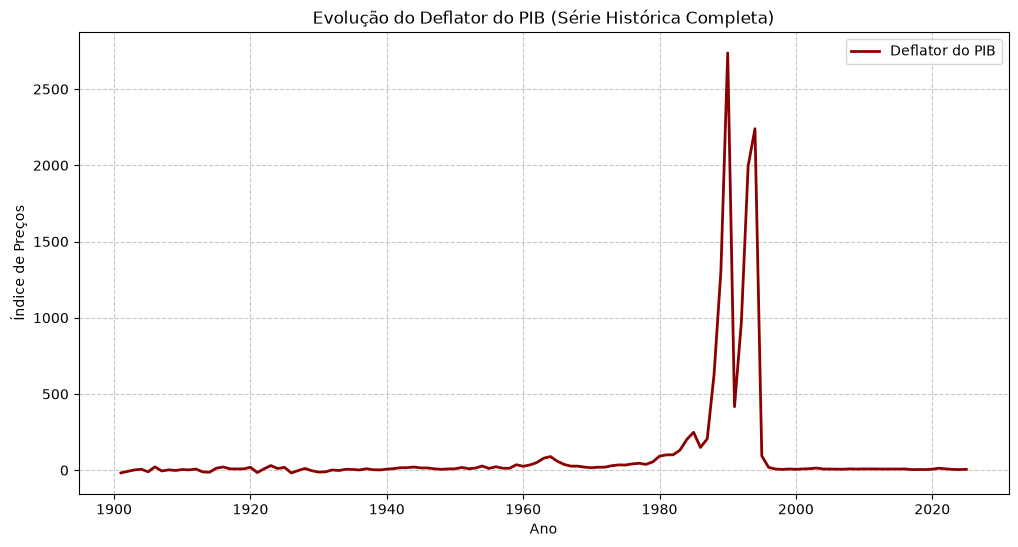

In [15]:
# deflator

import matplotlib.pyplot as plt

preco_deflator_total = df_hist['preco_deflator']

anos = range(1901, 1901 + len(preco_deflator_total))

plt.figure(figsize=(12, 6))

plt.plot(anos, preco_deflator_total, color='darkred', linewidth=2, label='Deflator do PIB')

plt.title('Evolução do Deflator do PIB (Série Histórica Completa)')
plt.xlabel('Ano')
plt.ylabel('Índice de Preços')
plt.legend()

plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

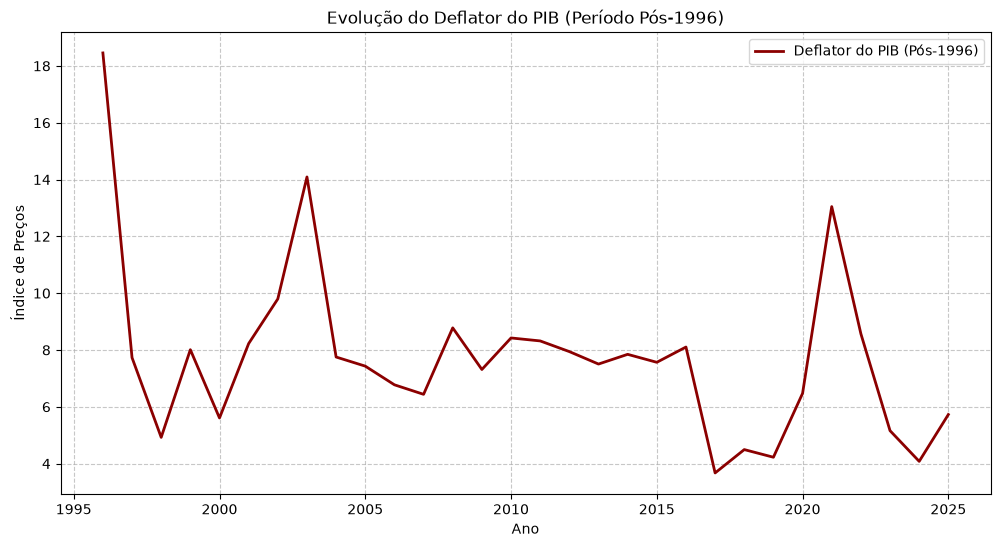

In [16]:
# deflator - pós-1994

import matplotlib.pyplot as plt

# Extrair a série de dados para o deflator do PIB a partir de 1996
# O índice 95 equivale ao ano de 1996 em uma série iniciada em 1901
preco_deflator_pos1996 = df_hist['preco_deflator'].iloc[95:]

# Criar a sequência temporal exata a partir de 1996 atrelada ao tamanho da série filtrada
anos = range(1996, 1996 + len(preco_deflator_pos1996))

# Definir o tamanho da figura com largura expandida
plt.figure(figsize=(12, 6))

# Criar o gráfico de linha relacionando os anos à variável preco_deflator no período pós-1996
plt.plot(anos, preco_deflator_pos1996, color='darkred', linewidth=2, label='Deflator do PIB (Pós-1996)')

# Adicionar título, rótulos e legenda aos eixos
plt.title('Evolução do Deflator do PIB (Período Pós-1996)')
plt.xlabel('Ano')
plt.ylabel('Índice de Preços')
plt.legend()

# Inserir grade de fundo para facilitar a leitura dos valores
plt.grid(True, linestyle='--', alpha=0.7)

# Exibir o gráfico final
plt.show()

3. Hiato do produto

#### **3. Hiato do produto**

O hiato do produto permite identificar a tendência de longo prazo (o produto potencial) e as flutuações de curto prazo (o produto observado). Assim, temos:

- **Produto potencial**: depende de fatores reais (capital, capital humano e tecnologia, entre outros) que mudam lentamente ao longo do tempo;
- **Produto observado**: reflete as flutuações da economia no curto prazo, oriundas da mudança de comportamento dos agentes e de choques;
- **Hiato do produto**: consiste na diferença entre produto observado e produto potencial. Permite identificar se está acima (produto observado > produto potencial) ou abaixo (produto observado < produto potencial), sugerindo a economia aquecida ou desaquecida, respectivamente.

A estratégia para estimar o hiato do produto consiste em aplicar um filtro estatístico que separe os ruídos de curto prazo e a tendência de longo prazo. Como padrão, a literatura tende a usar o filtro Hodrick-Prescott (HP), apesar das distorções nos extremos da série e da necessidade de calibragem dos parâmetros.

**Importante:** usamos a planilha data_hist


In [29]:
# pacotes

import pandas as pd
import numpy as np
from statsmodels.tsa.filters.hp_filter import hpfilter


# Carregar dados

df = '/home/elson29r/Área de trabalho/Academico/6 docencia e aulas/ufabc_2026_disciplinas/ufabc_2026.3_macro_I/model_data/aula03_data.xlsx'

# Série da taxa real de crescimento do PIB ao longo do século XX (1991 e 2025)

g = pd.read_excel(df, sheet_name="data_hist")["pib_txreal"] / 100   # variação percentual para decimal

log_pib = np.log1p(g.fillna(0)).cumsum()      # nível em log, base no primeiro ano
ciclo, tendencia = hpfilter(log_pib, lamb=100)

pib_potencial = 100 * np.exp(tendencia)       # produto potencial (índice, base 100)
hiato = 100 * (np.exp(ciclo) - 1)             # hiato do produto em %


       pib_txreal (%)  pib_potencial (índice)  cresc_potencial (%)  hiato (%)
count         125.000                 125.000              124.000    125.000
mean            4.491               6,088.610                4.240      0.073
std             4.320               6,859.574                1.990      3.848
min            -4.350                 110.293                0.663     -8.131
25%             1.390                 389.734                2.815     -2.846
50%             4.224               2,268.850                4.109      0.203
75%             7.800              10,725.714                5.803      2.748
max            14.365              21,178.400                8.721      9.532


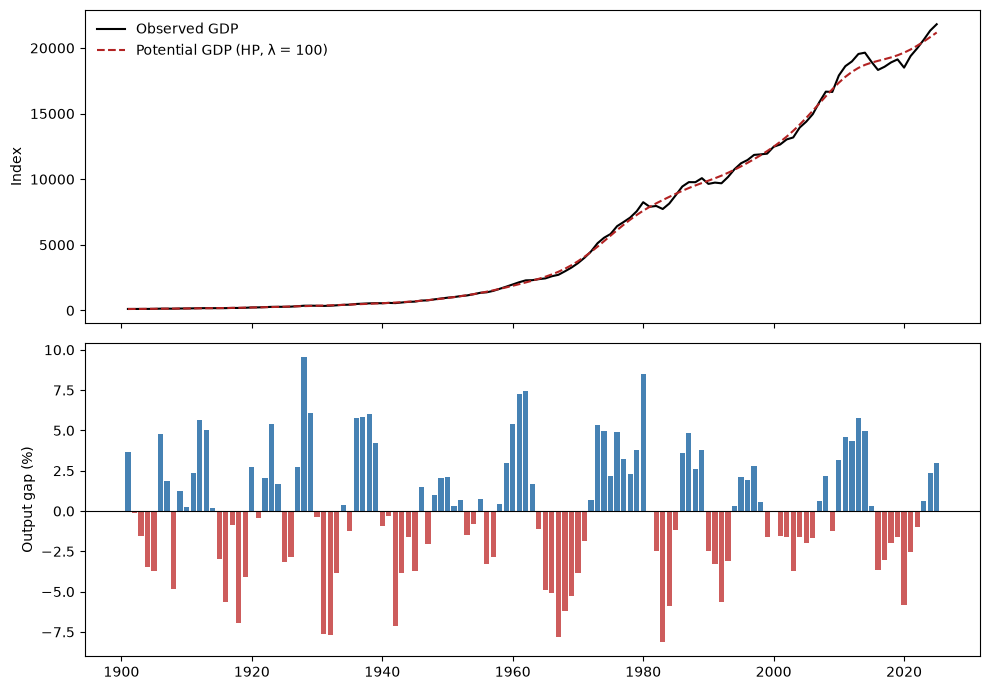

In [35]:
# visualização

import matplotlib.pyplot as plt

# Ano como índice (ajuste "ano" para o nome da coluna na sua planilha)
anos = pd.read_excel(df, sheet_name="data_hist")["ano"]

resultado = pd.DataFrame({
    "pib_txreal (%)": g * 100,
    "pib_potencial (índice)": pib_potencial,
    "cresc_potencial (%)": 100 * tendencia.diff(),
    "hiato (%)": hiato,
})
resultado.index = anos

# Visualização das estatísticas descritivas
pd.options.display.float_format = "{:,.3f}".format
print(resultado.describe().to_string())

# Gráfico: potencial e hiato
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

ax[0].plot(resultado.index, 100 * np.exp(log_pib).values, color="black", label="Observed GDP")
ax[0].plot(resultado.index, resultado["pib_potencial (índice)"], color="firebrick", ls="--", label="Potential GDP (HP, λ = 100)")
ax[0].set_ylabel("Index")
ax[0].legend(frameon=False)

ax[1].bar(resultado.index, resultado["hiato (%)"],
          color=np.where(resultado["hiato (%)"] >= 0, "steelblue", "indianred"))
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_ylabel("Output gap (%)")

plt.tight_layout()
plt.show()


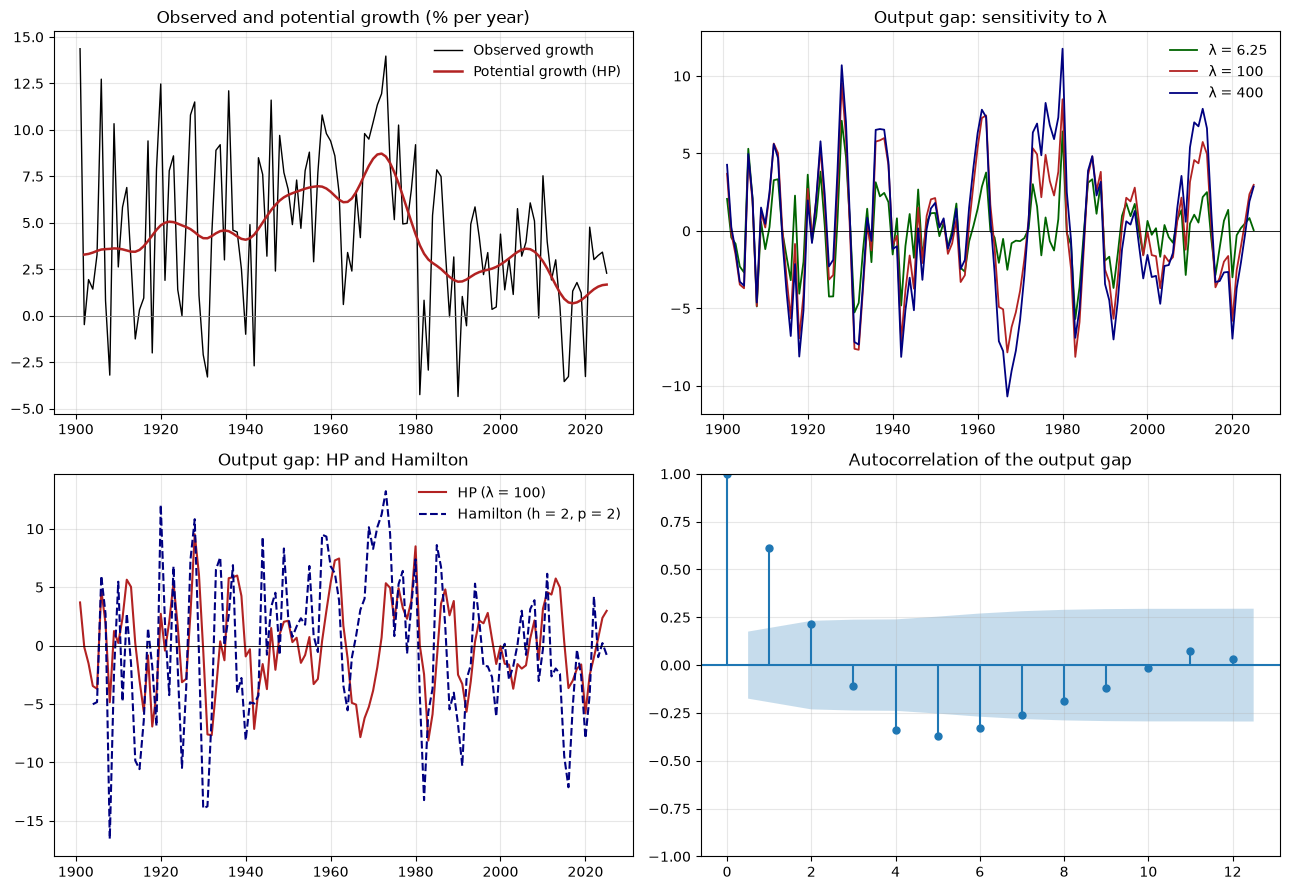

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.graphics.tsaplots import plot_acf

anos = pd.read_excel(df, sheet_name="data_hist")["ano"]
for s in (log_pib, tendencia, ciclo, hiato):
    s.index = anos

cresc_obs = 100 * g.set_axis(anos)
cresc_pot = 100 * tendencia.diff()

fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# 1. Crescimento observado contra crescimento potencial
ax[0, 0].plot(anos, cresc_obs, color="black", lw=1, label="Observed growth")
ax[0, 0].plot(anos, cresc_pot, color="firebrick", lw=1.8, label="Potential growth (HP)")
ax[0, 0].axhline(0, color="gray", lw=0.6)
ax[0, 0].set_title("Observed and potential growth (% per year)")
ax[0, 0].legend(frameon=False)

# 2. Robustez: hiato com diferentes valores de lambda
for lam, cor in [(6.25, "darkgreen"), (100, "firebrick"), (400, "navy")]:
    c, _ = hpfilter(log_pib, lamb=lam)
    ax[0, 1].plot(anos, 100 * (np.exp(c) - 1), color=cor, lw=1.3, label=f"λ = {lam}")
ax[0, 1].axhline(0, color="black", lw=0.6)
ax[0, 1].set_title("Output gap: sensitivity to λ")
ax[0, 1].legend(frameon=False)

# 3. Hiato do HP contra o hiato de Hamilton (h = 2, p = 2)
import statsmodels.api as sm
h, p = 2, 2
X = pd.concat([log_pib.shift(h + i) for i in range(p)], axis=1)
X.columns = [f"lag{h + i}" for i in range(p)]
base = pd.concat([log_pib.rename("y"), sm.add_constant(X)], axis=1).dropna()
hamilton = 100 * sm.OLS(base["y"], base.drop(columns="y")).fit().resid
ax[1, 0].plot(anos, hiato, color="firebrick", lw=1.5, label="HP (λ = 100)")
ax[1, 0].plot(hamilton.index, hamilton, color="navy", lw=1.5, ls="--", label="Hamilton (h = 2, p = 2)")
ax[1, 0].axhline(0, color="black", lw=0.6)
ax[1, 0].set_title("Output gap: HP and Hamilton")
ax[1, 0].legend(frameon=False)

# 4. Autocorrelação do hiato
plot_acf(hiato.dropna(), lags=12, ax=ax[1, 1])
ax[1, 1].set_title("Autocorrelation of the output gap")

for a in ax.ravel():
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("hiato_diagnosticos.png", dpi=300)
plt.show()

**FIM!!!**